# 08.3 Workshop on the Empirical evaluation of computational complexity

```
date: "Block 08"
author: "Daniel Lawson"
email: dan.lawson@bristol.ac.uk
output: html_document
version: 4.0.0
```

This workshop is about understanding computational complexity and exploring how to display this in python.

The source ideas for this workshop were inspired by
<https://towardsdatascience.com/understanding-time-complexity-with-python-examples-2bda6e8158a7>, though the implementations vary from that.

We will use the standard conventions for time complexity, i.e.

* $O(n)$ means that the maximum run time is bounded by a linear function in $n$

The algorithms below are close to deterministic. However, some algorithms vary in **Amortized** time, or in **average case** complexity. Repeating the analysis below with carefully chosen functions to demonstrate the different scaling would be very valuable.

In general, the distinction between worst-case and typical-case is important:

* if an algorithm may be run over most potential inputs, 
* if these might be chosen adversarially, or 
* if benchmarking of an algorithm is done for a rather different section of input space to where it might be deployed. 

The run time, and the memory requirement scaling are two of the most important quantities. Memory requirements are usually (but not always) easily bounded and few algorithms have massive variation in memory requirement (it is an undesirable feature for e.g. parallelisation).

### Technical note:

There is a tradeoff in making self-contained code, and correctly benchmarked code, which arises because of the need to generate data for the algorithms below. Rather than generate data externally we have elected to do it within the timing loop. 

Data generation is an $O(N)$ activity. This breaks some of the asymptotics, as generating data plus searching it using a logarithmic algorithm is asymptotically dominated by the generation time. However, the constants are sufficiently different that for the scale of experiments perfomed here, the search cost dominates and we see the correct behaviour!

This is an important lesson in the difference between theory and practice. Constants do matter.

In [22]:
from math import * # For log, etc
from timeit import Timer ## For timing 
from functools import partial ## For passing functions to be evaluated with arguments
import random ## For permutations
import numpy as np ## For numpy arrays for passing to:
import matplotlib.pyplot as plt ## For plotting with pylot
%matplotlib notebook

## Constant time complexity

A traditional constant time complexity algorithm is the "head" function, ie. to get the first M records of a dataset.

We won't benchmark this because it is not interesting.

## Logarithmic time complexity

The binary search algorithm is textbook as it is easily identified as logarithmic time complexity, because it splits the space into two equal parts at each iteration and therefore makes the surviving space "exponentially small".

Note that we define two versions of the algorithm, the "real version" which must be provided arguments, and a "randomised version" that just requires a data size, for benchmarking. See the technical note above regarding the cost of data generation.

In [23]:
## Logarithmic time algorithm
def binary_search(data, value): 
    ## Finds the index of the data that matches the value
    ## data must be sorted
    n = len(data)
    left = 0
    right = n - 1

    while left <= right:
        middle = floor((left + right) / 2)
        if value < data[middle]:
            right = middle - 1
        elif value > data[middle]:
            left = middle + 1
        else:
            return(middle)
    raise ValueError('Value is not in the list')

def r_binary_search(datalen):
    data=range(datalen)
    value=random.choice(data)
    return(binary_search(data,value))


In [24]:
## An example of using binary search
data = [1, 2, 3, 4, 5, 6, 7, 8, 9]
print(binary_search(data,5))

4


### Writing a timing function

Python has many ways to access the time before and after an evaluation. However the "Timer" function is the easiest to  work with in this context as it does the handling for us. See e.g. https://realpython.com/python-timer/ for many more options.

In [25]:
def time_fun(fun,l,rep=100):
    t=Timer(partial(fun,l))
    return([l,t.timeit(rep)/rep])

In [26]:
?Timer

Init signature:
Timer(
    stmt='pass',
    setup='pass',
    timer=<built-in function perf_counter>,
    globals=None,
)
Docstring:     
Class for timing execution speed of small code snippets.

The constructor takes a statement to be timed, an additional
statement used for setup, and a timer function.  Both statements
default to 'pass'; the timer function is platform-dependent (see
module doc string).  If 'globals' is specified, the code will be
executed within that namespace (as opposed to inside timeit's
namespace).

To measure the execution time of the first statement, use the
timeit() method.  The repeat() method is a convenience to call
timeit() multiple times and return a list of results.

The statements may contain newlines, as long as they don't contain
multi-line string literals.
Init docstring: Constructor.  See class doc string.
File:           ~/.local/share/uv/python/cpython-3.12.7-macos-aarch64-none/lib/python3.12/timeit.py
Type:           type
Subclasses:     Timer

## Linear time complexity - linear search

This is even simpler - we just look through the whole list for a particular item. Obviously a poor choice but occasionally makes sense if the data are not sorted or pre-prepared in any way.

In [27]:
## Linear time
def linear_search(data, value):
    for index in range(len(data)):
        if value == data[index]:
            return index
    raise ValueError('Value not found in the list')

def r_linear_search(datalen):
    data=range(datalen)
    value=random.choice(data)
    return(linear_search(data,value))

In [28]:
## An example of using linear search
data = [1, 2, 3, 4, 50, 6, 7, 8, 9]
print(linear_search(data,50))

4


## Quasilinear time algorithm: append with a lookup

Quasilinear means "linear, to logarithmic factors". So $O(N log(N)^x)$ for any fixed $x$ all count.

Quasilinear is often the gold-standard, because it allows you to a) look at all your data, and b) do something non-trivial with it. In high-throughput environments such as streaming, or will very large datasets, this can still be a problem; but the logarithmic term is usually on the same scale as a constant so beware the time complexity argument for superiority.

Here we just do a simple lookup for each item, trivially creating a quasilinear algorithm. [Merge sort](https://en.wikipedia.org/wiki/Merge_sort) is another famous example of such an algorithm.

In [29]:
## Quasilinear time: O(nlog(n))
def quasilinear_lookup(data1,data2):
    ## For each entry in data1, look up the index in data2 using binary search
    ## data2 must therefore be sorted
    result=[]
    for value in data1:
        result.append(binary_search(data2, value))
    return(result)

def r_quasilinear_lookup(datalen):
    data1=np.random.permutation(datalen)
    data2=range(datalen)
    return(quasilinear_lookup(data1,data2))

In [30]:
## An example of using quasilinear_lookup
quasilinear_lookup([0,40,20,10,30],[0,10,20,30,40])

[0, 4, 2, 1, 3]

## Quadratic time: bubble sort

Quadratic time is another key complexity milestone. It essentially arises out of double loops or "all-vs-all" comparisons.

[Bubble sort](https://en.wikipedia.org/wiki/Bubble_sort) is a classic example since it compares every item to half of the others, on average (and in the worst case).

In [31]:
## Quadratic time
def bubble_sort(data):
    swapped = True
    while swapped:
        swapped = False
        for i in range(len(data)-1):
            if data[i] > data[i+1]:
                data[i], data[i+1] = data[i+1], data[i]
                swapped = True
    return(data)

def r_bubble_sort(datalen):
    data=np.random.permutation(datalen)
    return(bubble_sort(data))

## Exponential time

You basically never want to use an exponential time algorithm unless the exponent is controlled. Brute-force password hacks are exponential time which is why long passwords are required; an additional character creates a huge additional bonus. ($26^n$ for lowercase characters of length $n$).

This example is a recursive algorithm for calculating the Fibonacci sequence. It is rather artificial as there are better ways, calculating them as an actual sequence, or using lookups. But its useful for illustration. It generates an exponential cost by computing the Fibonacci number as a computational tree with $O(2^n)$ nodes.

In [32]:
## Exponential time
def fibonacci(n):
    if n <= 1:
        return n
    return fibonacci(n-1) + fibonacci(n-2)


In [33]:
## Usage is rather simple
fibonacci(10)

55

## Factorial time

It will rarely be helpful to contemplate the difference between exponential and factorial time, but $n!$ grows larger than $2^n$. There are $n!$ permutations so computing these is the classic algorithm for illustration. We do occasionally do this, and we often want to sample such permutations, and/or know when to switch between exhaustive search and sampling.

In [34]:
## https://www.geeksforgeeks.org/generate-all-the-permutation-of-a-list-in-python/

# Python function to print permutations of a given list 
def permutation(lst): 
    # If lst is empty then there are no permutations 
    if len(lst) == 0: 
        return [] 
    # If there is only one element in lst then, only 
    # one permuatation is possible 
    if len(lst) == 1: 
        return [lst] 
    # Find the permutations for lst if there are 
    # more than 1 characters 
  
    l = [] # empty list that will store current permutation 
    # Iterate the input(lst) and calculate the permutation 
    for i in range(len(lst)): 
       m = lst[i] 
       # Extract lst[i] or m from the list.  remLst is 
       # remaining list 
       remLst = lst[:i] + lst[i+1:] 
  
       # Generating all permutations where m is first 
       # element 
       for p in permutation(remLst): 
           l.append([m] + p) 
    return l 

def r_permutation(len): 
    data = list(range(len))         
    permutation(data)

In [35]:
## Getting the results
data = list(range(4))         
permutation(data)

[[0, 1, 2, 3],
 [0, 1, 3, 2],
 [0, 2, 1, 3],
 [0, 2, 3, 1],
 [0, 3, 1, 2],
 [0, 3, 2, 1],
 [1, 0, 2, 3],
 [1, 0, 3, 2],
 [1, 2, 0, 3],
 [1, 2, 3, 0],
 [1, 3, 0, 2],
 [1, 3, 2, 0],
 [2, 0, 1, 3],
 [2, 0, 3, 1],
 [2, 1, 0, 3],
 [2, 1, 3, 0],
 [2, 3, 0, 1],
 [2, 3, 1, 0],
 [3, 0, 1, 2],
 [3, 0, 2, 1],
 [3, 1, 0, 2],
 [3, 1, 2, 0],
 [3, 2, 0, 1],
 [3, 2, 1, 0]]

## Benchmarking the algorithms

Now we run each algorithm at a suitably chosen range of inputs.

Note the value in coercing to a numpy array so that we can slice the results "the other way". Note also that we retain both the size of the data to be processed, and the time cost of the run.

In [36]:
binary_times=np.array(
    [time_fun(r_binary_search,floor(t)) for t in [1e0,1e1,1e2,1e3,1e4,1e5,1e6]]
)


In [37]:
quasilinear_times=np.array(
    [time_fun(r_quasilinear_lookup,floor(t)) for t in [1e0,1e1,1e2,1e3,1e4,2e4,3e4]]
)

In [38]:

linear_times=np.array(
    [time_fun(r_linear_search,floor(t)) for t in [1e0,1e1,1e2,1e3,1e4,1e5,1e6]]
)

In [39]:
bubblesort_times=np.array(
    [time_fun(r_bubble_sort,floor(t)) for t in [1e0,1e1,1e2,1e3]]
)


In [40]:
fibonacci_times=np.array(
    [time_fun(fibonacci,floor(t),rep=1) for t in [1,2,5,10,15,20,25,30,32,34,36,38]]
)


In [41]:
factorial_times=np.array(
    [time_fun(r_permutation,floor(t),rep=1) for t in [1,2,5,6,7,8,9,10]]
)

In [42]:
linear_times

array([[1.00000000e+00, 4.85839992e-07],
       [1.00000000e+01, 5.56250016e-07],
       [1.00000000e+02, 2.15083001e-06],
       [1.00000000e+03, 2.10537500e-05],
       [1.00000000e+04, 2.84782500e-04],
       [1.00000000e+05, 2.57298833e-03],
       [1.00000000e+06, 3.04834050e-02]])

## Plotting

Note that we standardize each dataset to start at $(1,1)$ so that any constant factors are stored similarly. This isn't perfect but it helps show the trend, separately from the base cost.

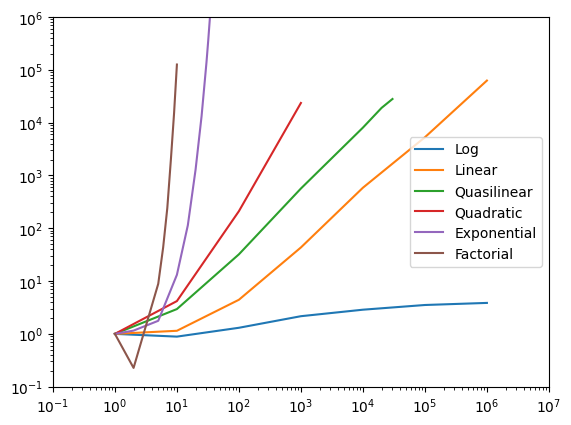

In [43]:
%matplotlib inline
plt.plot(binary_times[:,0]/binary_times[0,0],
         binary_times[:,1]/binary_times[0,1])
plt.plot(linear_times[:,0]/linear_times[0,0],
         linear_times[:,1]/linear_times[0,1])
plt.plot(quasilinear_times[:,0]/quasilinear_times[0,0],
         quasilinear_times[:,1]/quasilinear_times[0,1])
plt.plot(bubblesort_times[:,0]/bubblesort_times[0,0],
         bubblesort_times[:,1]/bubblesort_times[0,1])
plt.plot(fibonacci_times[:,0]/fibonacci_times[0,0],
         fibonacci_times[:,1]/fibonacci_times[0,1])
plt.plot(factorial_times[:,0]/factorial_times[0,0],
         factorial_times[:,1]/factorial_times[0,1])
plt.axis([.1, 1e7, .1, 1e6])
plt.xscale('log')
plt.yscale('log')
plt.legend(['Log','Linear','Quasilinear','Quadratic','Exponential','Factorial'])
plt.show()

## Final thoughts

Even with these simple functions, there are deviations from the theoretical time complexity. What can cause this?

* Memory paging
* CPU load/ Background processes
* Algorithmic non-triviality (amortization?)
* Any more?

Can you benchmark your own code as a function of data input size? Can you think of examples where runtime does not depend trivially on input size, or can even decrease at some sizes?

A question... how would you compute space/memory usage in real processes? Can you do this? 

* In Python, check out a [memory profiler](https://pypi.org/project/memory-profiler/).
* Notice that you have to call python separately for each of these requests. Why is that?
 
Now we've seen this content, it would be interesting to consider it as a component of an Assessment. 

* In Data Science, we often have multiple input scaling, e.g. data count, feature size, data variability can all affect runtime.
* Can you benchmark a set of non-trivial algorithms? How do they behave as a function of the input shape? 

## Data science algorithms in practice: exact versus approximate nearest neighbours

The examples above are textbook algorithms. We now apply the same analysis to a workhorse of data science: **$k$-Nearest Neighbours** ($k$NN), which underlies kNN classification and regression, recommender systems, clustering (e.g. DBSCAN), manifold learning (t-SNE, UMAP) and retrieval for Large Language Models.

The task: given $N$ training points in $d$ dimensions, and $M$ query points, find the $k$ closest training points to each query. We compare three approaches:

1. **Brute force** (exact). Compute the distance from each query to every training point. There is no build cost and each query costs $O(Nd)$, so $M$ queries cost $O(MNd)$.
2. **KD-tree** (exact). Build a binary tree that recursively splits space along one coordinate at a time (see the Binary Trees section of 08.2). Building costs $O(N \log N)$. A query costs roughly $O(\log N)$ in low dimension but degrades towards $O(N)$ as $d$ grows. This is the **curse of dimensionality**.
3. **Locality Sensitive Hashing** (LSH, approximate). Hash every training point into a **hash table** so that nearby points tend to share a bucket (see the Hash sections of 08.2). A query only examines points in its own bucket(s). Building costs $O(NdKL)$ and querying costs $O(dKL + Cd)$, where $C$ is the number of *candidate* points found in the buckets. The price is that we may **miss** some true neighbours.

The key questions are the ones from the lectures:

* How does the cost scale with $N$, and separately with $d$? (Multiple input scaling!)
* What is the trade-off between **build cost** and **query cost**, and when is building an index worth it (**amortization**)?
* What does approximation buy us, and what does it cost in **accuracy**?

### A note on benchmarking

Unlike above, here we generate the data **outside** the timing loop, and time the **build** and **query** stages separately. Data generation is $O(Nd)$, the same order as a brute force search, so the cheap trick used above would contaminate the answer.

We also do **not** standardise the curves to start at $(1,1)$. For approximate algorithms the constants are the whole point: LSH and brute force can have the *same* asymptotic complexity yet differ in run time by an order of magnitude.

Be aware that the three implementations are not equally optimised. The brute force uses `numpy` matrix multiplication, which calls highly optimised (and possibly multi-threaded) linear algebra libraries. The KD-tree is compiled Cython from `scikit-learn`. Our LSH is mostly plain Python. Compare the **slopes** with more confidence than the absolute values.

In [44]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.neighbors import KDTree

def make_data(n, d, n_query=200, seed=1):
    ## Clustered data: real data usually have structure, unlike uniform random points.
    ## Training and query points come from the same distribution.
    X, y = make_blobs(n_samples=n + n_query, n_features=d, centers=10,
                      cluster_std=3.0, random_state=seed)
    X = (X - X.mean(axis=0)) / X.std(axis=0)  ## standardise so LSH bucket width is comparable across d
    return X[n_query:], X[:n_query]

def best_time(fun, rep=3):
    ## The minimum over repeats is the least noisy estimate of the true cost
    return min(Timer(fun).repeat(repeat=rep, number=1))

### Brute force kNN

We use the identity $|q-x|^2 = |q|^2 - 2q\cdot x + |x|^2$ so that all of the distances are computed with a single matrix multiplication. The $|q|^2$ term is the same for every $x$, so it does not change the ranking and we drop it. `np.argpartition` finds the $k$ smallest values in $O(N)$ time, without the $O(N \log N)$ cost of a full sort.

We process the queries in chunks so that the $M \times N$ distance matrix does not exhaust memory. This trades space against time.

In [45]:
def brute_knn(X, Q, k=10, chunk=20):
    Xsq = (X**2).sum(axis=1)
    result = []
    for start in range(0, len(Q), chunk):
        D = Xsq[None, :] - 2 * Q[start:start+chunk] @ X.T  ## O(chunk * N * d)
        result.append(np.argpartition(D, k, axis=1)[:, :k]) ## O(chunk * N)
    return np.vstack(result)

### Locality Sensitive Hashing for Euclidean distance

We use the classic **p-stable** LSH of [Datar et al. (2004)](https://doi.org/10.1145/997817.997857). Each hash function projects a point onto a random direction $a$ and chops that line into intervals of width $w$:

$$h(x) = \left\lfloor \frac{a \cdot x + u}{w} \right\rfloor, \quad a \sim N(0, I_d),\ u \sim U(0, w).$$

Points that are close are likely to fall in the same interval, while distant points are not.

* **$K$ hashes per table**: a bucket is defined by all $K$ values, i.e. a cell of a random grid. Larger $K$ gives smaller buckets, so queries are faster but more true neighbours are missed.
* **$L$ tables**: we repeat with independent hashes and take the union of the buckets the query lands in. Larger $L$ catches more true neighbours, at a cost of $O(L)$ time and memory.
* **Bucket width $w$**: plays a similar role to $K$, setting the spatial scale of "nearby".

The $K$ integers are combined into a single key with random integer weights, which is itself a hash function (integer overflow is harmless: a collision just adds a few extra candidates). The table is a Python `dict`, i.e. a hash table with $O(1)$ average lookup. We then run brute force on just the candidates.

In [46]:
class LSHIndex:
    def __init__(self, K=6, L=10, w=3.0, seed=0):
        self.K, self.L, self.w, self.seed = K, L, w, seed

    def _keys(self, Z, t):
        ## Hash every row of Z with table t's K hash functions: O(n d K)
        cells = np.floor((Z @ self.A[t] + self.u[t]) / self.w).astype(np.int64)
        return cells @ self.r[t]  ## combine K integers into one key

    def fit(self, X):
        self.X = X
        d = X.shape[1]
        self.rng = np.random.default_rng(self.seed)  ## same hash functions every time we fit
        self.A = self.rng.normal(size=(self.L, d, self.K))
        self.u = self.rng.uniform(0, self.w, size=(self.L, self.K))
        self.r = self.rng.integers(1, 2**31, size=(self.L, self.K))
        self.tables = []
        for t in range(self.L):
            keys = self._keys(X, t)
            ## Group point indices by key: O(N log N) via a sort, then store in a dict
            order = np.argsort(keys, kind='stable')
            uniq, starts = np.unique(keys[order], return_index=True)
            self.tables.append(dict(zip(uniq, np.split(order, starts[1:]))))
        return self

    def query(self, Q, k=10):
        keys = np.stack([self._keys(Q, t) for t in range(self.L)])
        empty = np.empty(0, dtype=int)
        result = np.empty((len(Q), k), dtype=int)
        self.n_candidates = 0
        for i in range(len(Q)):
            cand = np.unique(np.concatenate(
                [self.tables[t].get(keys[t, i], empty) for t in range(self.L)]))
            if len(cand) <= k:  ## too few candidates: fall back to brute force (worst case O(N d)!)
                cand = np.arange(len(self.X))
            self.n_candidates += len(cand)
            D = ((self.X[cand] - Q[i])**2).sum(axis=1)  ## O(C d)
            result[i] = cand[np.argpartition(D, k)[:k]]
        self.n_candidates /= len(Q)  ## average candidates per query
        return result

def recall(approx, exact):
    ## Fraction of the true k nearest neighbours that were found
    return np.mean([len(set(a) & set(e)) / len(e) for a, e in zip(approx, exact)])

In [47]:
## A quick check that everything agrees
X, Q = make_data(10000, 10)
exact = brute_knn(X, Q)
tree_idx = KDTree(X).query(Q, k=10, return_distance=False)
lsh = LSHIndex().fit(X)
lsh_idx = lsh.query(Q)
print('KD-tree recall:', recall(tree_idx, exact))
print('LSH recall:', recall(lsh_idx, exact),
      '| candidates per query:', round(lsh.n_candidates), 'of', len(X))

KD-tree recall: 1.0
LSH recall: 0.7455000000000002 | candidates per query: 240 of 10000


### Scaling with the number of data points $N$

We fix $d=10$, $k=10$, $M=200$ queries and the LSH parameters $(K, L, w)$. This takes around 10 seconds on a laptop.

In [48]:
def benchmark_knn(n, d, k=10, K=6, L=10):
    X, Q = make_data(n, d)
    w = 3.0 * np.sqrt(d / 10)  ## typical distances grow like sqrt(d), so scale the bucket width to match
    exact = brute_knn(X, Q, k)
    row = {'n': n, 'd': d}
    row['brute_query'] = best_time(lambda: brute_knn(X, Q, k))
    row['kd_build'] = best_time(lambda: KDTree(X))
    tree = KDTree(X)
    row['kd_query'] = best_time(lambda: tree.query(Q, k=k, return_distance=False))
    lsh = LSHIndex(K=K, L=L, w=w)
    row['lsh_build'] = best_time(lambda: lsh.fit(X))
    row['lsh_query'] = best_time(lambda: lsh.query(Q, k))
    row['lsh_recall'] = recall(lsh.query(Q, k), exact)
    row['lsh_cand_frac'] = lsh.n_candidates / n
    return row

knn_N = [benchmark_knn(n, d=10) for n in [1000, 3000, 10000, 30000, 100000, 300000]]
for row in knn_N:
    print({key: float(f'{v:.3g}') for key, v in row.items()})

{'n': 1000.0, 'd': 10.0, 'brute_query': 0.00339, 'kd_build': 0.000218, 'kd_query': 0.00214, 'lsh_build': 0.00435, 'lsh_query': 0.00464, 'lsh_recall': 0.621, 'lsh_cand_frac': 0.123}
{'n': 3000.0, 'd': 10.0, 'brute_query': 0.00549, 'kd_build': 0.00047, 'kd_query': 0.00208, 'lsh_build': 0.00704, 'lsh_query': 0.00417, 'lsh_recall': 0.668, 'lsh_cand_frac': 0.0342}
{'n': 10000.0, 'd': 10.0, 'brute_query': 0.0156, 'kd_build': 0.00184, 'kd_query': 0.00382, 'lsh_build': 0.0161, 'lsh_query': 0.00863, 'lsh_recall': 0.746, 'lsh_cand_frac': 0.024}
{'n': 30000.0, 'd': 10.0, 'brute_query': 0.0474, 'kd_build': 0.007, 'kd_query': 0.00782, 'lsh_build': 0.0383, 'lsh_query': 0.0228, 'lsh_recall': 0.85, 'lsh_cand_frac': 0.0233}
{'n': 100000.0, 'd': 10.0, 'brute_query': 0.17, 'kd_build': 0.0303, 'kd_query': 0.0195, 'lsh_build': 0.117, 'lsh_query': 0.0773, 'lsh_recall': 0.886, 'lsh_cand_frac': 0.0241}
{'n': 300000.0, 'd': 10.0, 'brute_query': 0.442, 'kd_build': 0.125, 'kd_query': 0.0693, 'lsh_build': 0.368, 

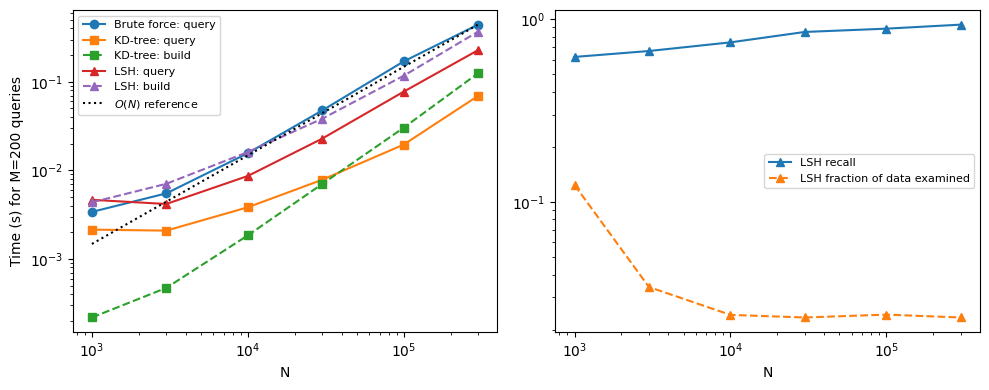

In [49]:
def col(rows, key):
    return np.array([row[key] for row in rows])

N = col(knn_N, 'n')
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(N, col(knn_N, 'brute_query'), 'o-', label='Brute force: query')
ax[0].plot(N, col(knn_N, 'kd_query'), 's-', label='KD-tree: query')
ax[0].plot(N, col(knn_N, 'kd_build'), 's--', label='KD-tree: build')
ax[0].plot(N, col(knn_N, 'lsh_query'), '^-', label='LSH: query')
ax[0].plot(N, col(knn_N, 'lsh_build'), '^--', label='LSH: build')
ax[0].plot(N, col(knn_N, 'brute_query')[-1] * N / N[-1], 'k:', label='$O(N)$ reference')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('N'); ax[0].set_ylabel('Time (s) for M=200 queries')
ax[0].legend(fontsize=8)

ax[1].plot(N, col(knn_N, 'lsh_recall'), '^-', label='LSH recall')
ax[1].plot(N, col(knn_N, 'lsh_cand_frac'), '^--', label='LSH fraction of data examined')
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('N')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

We can estimate the empirical complexity from the **local slope** of the log-log plot between consecutive values of $N$. A slope of 1 is linear, 2 is quadratic, and a slope near 0 is logarithmic or constant. Looking at local slopes, rather than one fitted line, shows where the behaviour changes, for example when fixed overheads stop dominating or when the data stop fitting in the CPU cache.

In [50]:
def local_slopes(x, t):
    return np.diff(np.log(t)) / np.diff(np.log(x))

for key in ['brute_query', 'kd_build', 'kd_query', 'lsh_build', 'lsh_query']:
    print(f'{key:12s} local slopes:', np.round(local_slopes(N, col(knn_N, key)), 2))

brute_query  local slopes: [0.44 0.87 1.01 1.06 0.87]
kd_build     local slopes: [0.7  1.13 1.22 1.22 1.29]
kd_query     local slopes: [-0.02  0.5   0.65  0.76  1.15]
lsh_build    local slopes: [0.44 0.69 0.79 0.93 1.04]
lsh_query    local slopes: [-0.1   0.6   0.88  1.01  0.98]


Things to notice:

* **Brute force** is close to linear in $N$, as expected.
* **KD-tree queries** grow sublinearly (a local slope of roughly 0.5-0.6), but well short of the ideal $O(\log N)$, because in $d=10$ the search must backtrack into many neighbouring cells. The **build** is quasilinear, and we pay it only once. You may see the slope jump at the largest $N$: the data (about 24MB) no longer fit in the CPU cache, a reminder of the Final thoughts above.
* **LSH queries** are still $O(N)$ with these settings! With $K$, $L$ and $w$ fixed, each bucket holds a roughly constant **fraction** of the data, so $C \propto N$ (see the right panel). What we have gained is a much smaller **constant**: we compute distances to only about 2% of the data. At small $N$ the fixed per-query Python overhead dominates and the local slope is near 0, so LSH is *slower* than brute force. As $N$ grows the slope approaches 1.
* **LSH recall** changes with $N$, even though the algorithm has not changed. As $N$ grows the true neighbours get closer together, so they are more likely to share a bucket. **The accuracy of an approximate algorithm can depend on the input size**, so it must be benchmarked alongside the run time.

LSH theory (Indyk and Motwani 1998) shows that by letting $K$ grow like $\log N$, and $L$ like $N^\rho$ for some $\rho<1$ that depends on the approximation required, the query cost becomes **sublinear**, $O(N^\rho)$, with guaranteed accuracy.

### Scaling with the dimension $d$

Now we fix $N=30000$ and vary $d$. We keep $K$ and $L$ fixed, and scale the bucket width $w$ with $\sqrt{d}$ so that buckets stay at a comparable size relative to typical distances.

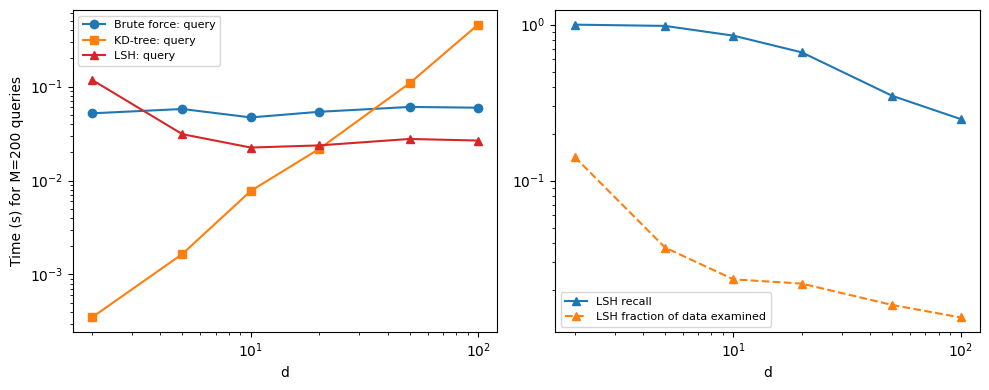

In [51]:
knn_d = [benchmark_knn(30000, d) for d in [2, 5, 10, 20, 50, 100]]
D = col(knn_d, 'd')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(D, col(knn_d, 'brute_query'), 'o-', label='Brute force: query')
ax[0].plot(D, col(knn_d, 'kd_query'), 's-', label='KD-tree: query')
ax[0].plot(D, col(knn_d, 'lsh_query'), '^-', color='C3', label='LSH: query')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('d'); ax[0].set_ylabel('Time (s) for M=200 queries')
ax[0].legend(fontsize=8)
ax[1].plot(D, col(knn_d, 'lsh_recall'), '^-', label='LSH recall')
ax[1].plot(D, col(knn_d, 'lsh_cand_frac'), '^--', label='LSH fraction of data examined')
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('d')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

* **Brute force** is $O(d)$, and because of the efficient matrix multiplication it barely notices $d$ at this scale.
* The **KD-tree** is excellent in low dimension but degrades quickly. In high dimension almost every cell of the tree has to be checked, so we pay the brute-force cost *plus* the overhead of navigating the tree. This is the **curse of dimensionality**, and it is why tree-based methods are rarely used for, e.g., text embeddings with $d \approx 1000$.
* **LSH** keeps its query cost roughly constant (except at very low $d$, where buckets are large), because it still examines only a small fraction of the data, but its **recall** collapses as $d$ grows. The curse of dimensionality has not gone away: the exact method pays for it in **time**, the approximate method in **accuracy**. A fair comparison would tune $(K, L, w)$ for each $d$ to reach a target recall, such as 0.9, and then compare costs. (Exercise 3 below.)

### Exercises

1. **Memory.** What is the space complexity of each index in terms of $N$, $d$, $K$ and $L$? Which would you choose if $N=10^9$?
2. **Real data.** Repeat the analysis on a real dataset, e.g. `sklearn.datasets.fetch_covtype` ($N \approx 580{,}000$, $d=54$), or on embeddings from the Topic Models workshop. Real data usually have a low **intrinsic** dimension. Does the KD-tree fare better than its nominal $d$ suggests?

For production use, libraries such as [FAISS](https://github.com/facebookresearch/faiss), [Annoy](https://github.com/spotify/annoy), [HNSW](https://github.com/nmslib/hnswlib) and [pynndescent](https://github.com/lmcinnes/pynndescent) implement much more sophisticated approximate nearest-neighbour searches. The [ANN benchmarks](https://ann-benchmarks.com/) site compares them with exactly this kind of accuracy-versus-speed analysis.

## Portfolio Question 8.3.P - Empirical complexity

* You benchmark an algorithm whose theoretical complexity is $O(N \log N)$, but the log-log plot of run time against $N$ has a slope of 0 at small $N$, about 1 in the middle, and above 1 at large $N$.
  - What could cause each part of this curve?
  - When should you trust the theoretical complexity over the measurement, and when the reverse?
  - How would you design a benchmark that you would trust to choose between two algorithms for a real deployment?